# GISC405 Climate Analytics Lab: Mapping Aotearoa New Zealand with Geospatial Embeddings

**Notebook:** Dr. Morteza Karimzadeh  

We ended the CNN notebook with an important idea: a **simple prediction head can work very well when the representation underneath it is good**.

Today we turn that idea around. Instead of learning the representation ourselves with a CNN, we will use **pretrained geospatial embeddings** to see: **How well can pretrained geospatial representations help us reconstruct a New Zealand climate field from sparse observations (labels)?**

The principal pretrained representations in this lab are:

- **SLED** — a coordinate-only location encoder distilled from Earth-observation foundation-model teachers. In practice, it provides a relatively small model that can sit in memory, take longitude/latitude, and immediately output an embedding;
- **SatCLIP** — a coordinate-only location encoder trained contrastively against satellite imagery. It similarly takes longitude/latitude and immediately outputs a learned location embedding;
- **AlphaEarth Foundations / Satellite Embedding V1** — a 64-D local Earth-observation embedding sampled at each NZ location. Here Google has already processed large amounts of geospatial data and we retrieve the resulting embedding for each location.

The downstream learner is deliberately tiny: a **single `Dense(1)` layer in TensorFlow/Keras** to keep consistent with our previous labs. In the future, I suggest becoming comfortable with PyTorch (and PyTorch Lightning) as well.

SLED and SatCLIP are released in PyTorch, but we use PyTorch only for frozen feature extraction. I provide AlphaEarth as a precomputed `.npz` file so that you do not need to query Earth Engine during class. Once an embedding matrix has been generated or loaded, **all downstream learning, evaluation, and ablations are TensorFlow/Keras** to keep the workflow consistent with our previous labs and easy to inspect.

We will work through **mean annual temperature** together in class. After that, you will choose one of the alternative climate targets from the same multivariable class file, change `TARGET_KEY`, rerun the workflow, make any changes needed for your variable, and answer the questions throughout for that target.

By the end of this lab you should be able to:

1. Explain what a geospatial embedding is and how it relates to raw latitude/longitude.
2. Generate **SLED and SatCLIP location embeddings directly from longitude/latitude**.
3. Load **AlphaEarth embeddings** for the same NZ climate-grid locations.
4. Fit the **same TensorFlow linear probe** to multiple frozen representations.
5. Evaluate spatial generalization using **held-out geographic blocks**, not just a random split.
6. Compare **elevation only**, **embedding only**, and **embedding + elevation** fairly.
7. Interpret residual maps and discuss what each representation may or may not contain.


## 0. What are we comparing?

| Representation | Input needed at prediction time | What it represents | Used Here? |
|---|---|---|---|
| Raw coordinates | longitude, latitude | position only | yes |
| Random Fourier Features (RFF) | longitude, latitude | a flexible but **untrained** spatial basis | yes |
| Elevation | elevation at the location | one conventional ancillary variable | yes |
| **SLED** | longitude, latitude | EO information distilled into a continuous location function | **yes** |
| **AlphaEarth Satellite Embedding** | sampled EO embedding for a place/year | a 64-D learned local Earth-surface representation | **yes** |
| **SatCLIP** | longitude, latitude | a location representation contrastively aligned with Sentinel-2 imagery | **yes** |
| Tessera | EO embedding for a place/year | a learned local EO representation | optional extension |
| OlmoEarth | EO modalities / generated embeddings | a learned multimodal Earth representation | optional extension |

These are **not perfectly equivalent representations**. They are created using different philosophies, with entities with different compute capabilities, and different use case goals.

SLED and SatCLIP are *location encoders*: after pretraining, they require only coordinates to output embeddings. AlphaEarth/Tessera provide embeddings derived from EO observations at the location, look-up style. We freeze each representation and ask the same downstream question using the **same TensorFlow probe, same labels, and same spatial split**.

Two comparisons are especially useful:

> **What can be predicted from a learned function of location alone (SLED/SatCLIP), versus from a locally observed EO representation (AlphaEarth)?**

and

> **How much do the embeddings add beyond a simple physical ancillary variable such as elevation?**


## 1. Setup

Good news: This lab **does not need a GPU**. In Colab, we will deliberately use the **CPU-only runtime** to make that point: `Runtime -> Change runtime type -> Hardware accelerator -> CPU`.

This is partially to show that with pretrained embeddings, a downstream task may not need as much compute.

You are completely free to use a GPU runtime if you prefer. The SLED and SatCLIP feature-extraction code will use a GPU automatically if one is available, but the dataset and downstream probes are small enough that it is unnecessary for this lab.

SLED and SatCLIP themselves are released as PyTorch models (and so will future models). We use PyTorch only as a feature-extraction utility.

So we essentially load a precomputed feature table: **we do not train SLED or SatCLIP or AlphaEarth in this lab**. We use and evaluate them for our task, which is much closer to a realistic downstream application.


In [1]:
# Core libraries
import re
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU detected (optional, not required):", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow version: 2.20.0
GPU detected (optional, not required): True


### Reading class files directly from my Google Drive

For files I provide, you should not need to download anything to your computer and then upload it to Colab. The helper below authenticates your Google account once, reads a file that I have shared with you by its Drive link or file ID, and caches a temporary copy in the Colab runtime.

That temporary runtime copy is just how Python opens the file; there is **no manual download/upload step for you**. On Windows or another local Python environment, the same notebook simply uses the local file if it already exists beside the notebook.

I use one generic loader for `.npz` files and other binary class files rather than writing a separate Drive-reading function for every dataset.


In [2]:
%pip -q install pydrive2

_DRIVE_CLIENT = None


def _google_drive_file_id(file_id_or_url):
    """Accept either a raw Google Drive file ID or a normal share URL."""
    if file_id_or_url is None:
        return None
    value = str(file_id_or_url).strip()
    if not value:
        return None

    patterns = [
        r"/file/d/([A-Za-z0-9_-]+)",
        r"[?&]id=([A-Za-z0-9_-]+)",
    ]
    for pattern in patterns:
        match = re.search(pattern, value)
        if match:
            return match.group(1)
    return value


def _get_drive_client():
    """Authenticate once per Colab runtime and return a PyDrive2 client."""
    global _DRIVE_CLIENT
    if _DRIVE_CLIENT is not None:
        return _DRIVE_CLIENT

    try:
        from google.colab import auth
    except ImportError as exc:
        raise RuntimeError("Google Drive authentication is only needed in Colab.") from exc

    from oauth2client.client import GoogleCredentials
    from pydrive2.auth import GoogleAuth
    from pydrive2.drive import GoogleDrive

    auth.authenticate_user()
    gauth = GoogleAuth()
    gauth.credentials = GoogleCredentials.get_application_default()
    _DRIVE_CLIENT = GoogleDrive(gauth)
    return _DRIVE_CLIENT


def fetch_drive_file(file_id_or_url, local_name, overwrite=False):
    """Read one shared class file from Google Drive into the notebook runtime.

    In Colab, authenticate with the Google account that has access to the file.
    Outside Colab, place the file next to the notebook and this function uses it directly.
    """
    path = Path(local_name)
    if path.exists() and not overwrite:
        print(f"Using cached/local file: {path}")
        return path

    file_id = _google_drive_file_id(file_id_or_url)
    if file_id is None:
        raise FileNotFoundError(
            f"{path} is not present locally and no Google Drive link/file ID was supplied."
        )

    try:
        drive = _get_drive_client()
    except RuntimeError as exc:
        raise FileNotFoundError(
            f"{path} is not present locally. Outside Colab, place the file next to the notebook."
        ) from exc

    downloaded = drive.CreateFile({"id": file_id})
    downloaded.GetContentFile(str(path))
    print(f"Loaded from my Google Drive: {path}")
    return path


## 2. Load the New Zealand climate targets

We will work through **mean annual temperature** together first. It is an easier-to-understand target and gives us a common example for learning how the embeddings and probes work.

The climate targets come from the New Zealand Climate Projections Core Public Dataset (multi-model mean, MMM). I have already extracted and aligned a useful set of annual baseline and late-century change variables into one small class file:

```text
nz_climate_targets_multivariable.npz
```

Dataset documentation:  
https://climatedata.environment.govt.nz/core-public-dataset.html

The file contains the same 11,491 NZ land-grid locations for every target, so **we do not need to download or extract the original NetCDF/parquet data during this lab**.

For the in-class example we use:

- target key: `T_ANN_baseline_1995_2014`
- variable: mean daily air temperature (`T`)
- model: multi-model mean (`MMM`)
- baseline: 1995–2014
- period: annual (`ANN`)

The source climate grid was originally distributed using NZGD49 coordinates. I have already done that coordinate-system bookkeeping in the class file: `lon`/`lat` are **WGS84** coordinates ready for SLED, SatCLIP, and plotting, while `x_nztm`/`y_nztm` are **NZTM2000** coordinates ready for spatial blocks and distance calculations. We do not need to perform CRS transformations in this lab.

**Important:** these are gridded climate reference fields, not sets of raw weather-station measurements. We deliberately hide most grid values and treat the remaining labelled locations as sparse supervision.

For your assignment, **do not change the Drive link**. Change only `TARGET_KEY` below to one of the alternatives printed by the notebook, then rerun from the top.


In [3]:
# One shared class file contains the in-class temperature target and all assignment alternatives.
TARGETS_DRIVE_LINK = "https://drive.google.com/file/d/1fFcvPWnsMMi5YjANMxlHdtavPU0eW_zu/view?usp=sharing"
TARGETS_PATH = "nz_climate_targets_multivariable.npz"

# This is the target we will work through together in class.
# For the assignment, change ONLY this key, then rerun the notebook from the top.
TARGET_KEY = "T_ANN_baseline_1995_2014"

# Read the shared file from my Drive (or use a local copy if it already exists).
targets_file = fetch_drive_file(TARGETS_DRIVE_LINK, TARGETS_PATH)
target_data = np.load(targets_file, allow_pickle=False)

required = {
    "row_id", "lon", "lat", "x_nztm", "y_nztm", "targets", "target_keys",
    "target_names", "target_units", "target_categories", "target_kinds",
    "target_periods", "target_scenarios", "target_roles", "coordinate_crs",
    "projected_crs",
}
missing = required.difference(target_data.files)
if missing:
    raise ValueError(
        f"Climate target file is missing: {sorted(missing)}. "
        "Make sure you are using the WGS84/NZTM-prepared class file."
    )

print("Loaded:", TARGETS_PATH)
print("Locations:", len(target_data["row_id"]))
print("Targets:", len(target_data["target_keys"]))
print("Geographic coordinates:", str(target_data["coordinate_crs"].item()))
print("Projected coordinates:", str(target_data["projected_crs"].item()))


Loaded from my Google Drive: nz_climate_targets_multivariable.npz
Loaded: nz_climate_targets_multivariable.npz
Locations: 11491
Targets: 21
Geographic coordinates: EPSG:4326 (WGS84)
Projected coordinates: EPSG:2193 (NZTM2000)


In [4]:
# Inspect the targets available in the shared class file.
target_catalog = pd.DataFrame({
    "target_key": target_data["target_keys"].astype(str),
    "name": target_data["target_names"].astype(str),
    "units": target_data["target_units"].astype(str),
    "category": target_data["target_categories"].astype(str),
    "kind": target_data["target_kinds"].astype(str),
    "period": target_data["target_periods"].astype(str),
    "scenario": target_data["target_scenarios"].astype(str),
    "role": target_data["target_roles"].astype(str),
})

display(target_catalog)


,target_key,name,units,category,kind,period,scenario,role
0,PR_ANN_baseline_1995_2014,"Total rainfall, annual 1995-2014 baseline",mm,rainfall,baseline,1995-2014,historical baseline,alternative
1,R99pVAL_ANN_baseline_1995_2014,"Heavy rainfall (99th percentile), annual 1995-...",mm,rainfall extremes,baseline,1995-2014,historical baseline,alternative
2,R99pVALWet_ANN_baseline_1995_2014,Heavy rainfall (99th percentile on wet days >=...,mm,rainfall extremes,baseline,1995-2014,historical baseline,alternative
3,RR1mm_ANN_baseline_1995_2014,"Number of rainy days (>=1 mm), annual 1995-201...",days,rainfall frequency,baseline,1995-2014,historical baseline,alternative
4,RR25mm_ANN_baseline_1995_2014,"Number of very rainy days (>25 mm), annual 199...",days,rainfall extremes,baseline,1995-2014,historical baseline,alternative
5,DD1mm_ANN_baseline_1995_2014,"Number of dry days (<1 mm), annual 1995-2014 b...",days,dryness,baseline,1995-2014,historical baseline,alternative
6,PEDsrad_ANN_baseline_1995_2014,"Potential evapotranspiration deficit, annual 1...",mm,water balance,baseline,1995-2014,historical baseline,alternative
7,hurs_ANN_baseline_1995_2014,"Average relative humidity, annual 1995-2014 ba...",%,humidity,baseline,1995-2014,historical baseline,alternative
8,rsds_ANN_baseline_1995_2014,"Incoming solar radiation, annual 1995-2014 bas...",W/m2,radiation,baseline,1995-2014,historical baseline,alternative
9,sfcWind_ANN_baseline_1995_2014,"Average daily 10 m wind speed, annual 1995-201...",m/s,wind,baseline,1995-2014,historical baseline,alternative


In [5]:
# Select one target column by key.
target_keys = target_data["target_keys"].astype(str)
matches = np.where(target_keys == TARGET_KEY)[0]
if len(matches) != 1:
    raise KeyError(
        f"TARGET_KEY={TARGET_KEY!r} was not found exactly once. "
        "Choose a key from target_catalog above."
    )

target_j = int(matches[0])
target_values = target_data["targets"][:, target_j].astype(np.float32)

climate_df = pd.DataFrame({
    "row_id": target_data["row_id"].astype(int),
    "lon": target_data["lon"].astype(np.float32),       # WGS84
    "lat": target_data["lat"].astype(np.float32),       # WGS84
    "x_nztm": target_data["x_nztm"].astype(np.float32), # metres, NZTM2000
    "y_nztm": target_data["y_nztm"].astype(np.float32), # metres, NZTM2000
    "target": target_values,
})

# The class file is complete for the targets provided, but keep this check explicit.
finite = np.isfinite(climate_df["target"].to_numpy())
if not finite.all():
    print(f"Dropping {(~finite).sum():,} locations with missing target values.")
    climate_df = climate_df.loc[finite].reset_index(drop=True)

TARGET_NAME = str(target_data["target_names"][target_j])
TARGET_UNITS = str(target_data["target_units"][target_j])
TARGET_CATEGORY = str(target_data["target_categories"][target_j])
TARGET_KIND = str(target_data["target_kinds"][target_j])
TARGET_PERIOD = str(target_data["target_periods"][target_j])
TARGET_SCENARIO = str(target_data["target_scenarios"][target_j])
TARGET_LABEL = f"{TARGET_NAME} ({TARGET_UNITS})" if TARGET_UNITS else TARGET_NAME

print("Selected target:", TARGET_KEY)
print("Name:", TARGET_NAME)
print("Units:", TARGET_UNITS)
print("Category:", TARGET_CATEGORY)
print("Kind / period / scenario:", TARGET_KIND, "/", TARGET_PERIOD, "/", TARGET_SCENARIO)
print("Grid locations:", len(climate_df))


Selected target: T_ANN_baseline_1995_2014
Name: Average daily air temperature (Tmean), annual 1995-2014 baseline
Units: Deg C
Category: temperature
Kind / period / scenario: baseline / 1995-2014 / historical baseline
Grid locations: 11491


### Inspecting the selected target

Before modelling anything, inspect the selected field and its metadata. The plotting and evaluation code below is intentionally target-agnostic: when you change `TARGET_KEY`, the name and units used throughout the notebook update automatically.


In [6]:
print("Target key:", TARGET_KEY)
print("Target name:", TARGET_NAME)
print("Units:", TARGET_UNITS)
print("Category:", TARGET_CATEGORY)
print()
print(climate_df["target"].describe())


Target key: T_ANN_baseline_1995_2014
Target name: Average daily air temperature (Tmean), annual 1995-2014 baseline
Units: Deg C
Category: temperature

count    11491.000000
mean        10.420308
std          2.912051
min         -0.414923
25%          8.597773
50%         10.546045
75%         12.573679
max         16.791285
Name: target, dtype: float64


In [7]:
# Sanity checks: all downstream representations use these same row IDs and locations.
assert climate_df["row_id"].is_unique, "row_id must be unique."
assert np.isfinite(climate_df[["lon", "lat", "x_nztm", "y_nztm", "target"]].to_numpy()).all()

print(climate_df.shape)
climate_df.head()


(11491, 6)


,row_id,lon,lat,x_nztm,y_nztm,target
0,0,172.875168,-34.423153,1588529.500,6190917.0,16.561029
1,1,172.675171,-34.473152,1570169.875,6185332.0,16.708277
2,2,172.725174,-34.473152,1574761.750,6185345.5,16.679010
3,3,172.775177,-34.473152,1579353.750,6185356.5,15.962458
4,4,172.825165,-34.473156,1583944.375,6185365.5,16.677607


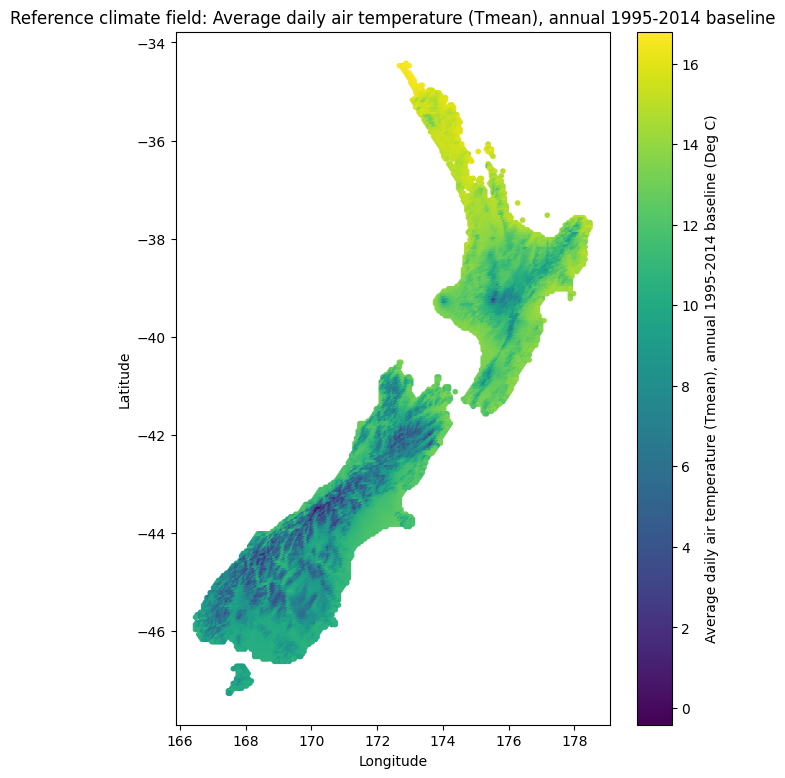

count    11491.000000
mean        10.420308
std          2.912051
min         -0.414923
25%          8.597773
50%         10.546045
75%         12.573679
max         16.791285
Name: target, dtype: float64


In [8]:
# First look at the target climate field
plt.figure(figsize=(7, 9))
sc = plt.scatter(
    climate_df["lon"], climate_df["lat"],
    c=climate_df["target"], s=9
)
plt.colorbar(sc, label=TARGET_LABEL)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Reference climate field: {TARGET_NAME}")
plt.show()

print(climate_df["target"].describe())


### Question 1

Before modelling anything, describe the broad spatial pattern you see.

- What large-scale climate gradients are visible?
- Where would you expect elevation to matter?
- For our in-class temperature example, why might latitude/longitude alone already be a surprisingly strong predictor?
- When you rerun the notebook for your assignment target, which of these expectations change?


## 3. Create spatial train / test blocks

A random train/test split is often misleading for spatial data because nearby locations tend to have similar climates.

### Spatial split 1: 100 × 100 km checkerboard

We first divide New Zealand into 100 × 100 km blocks using the **NZTM2000 coordinates already stored in the class file**. Neighboring blocks alternate deterministically between training and test regions.

This relatively coarse spatial holdout provides strong spatial separation, but we should inspect whether important environmental features — particularly the Southern Alps — are adequately represented in both training and test regions.


In [9]:
# The class file already contains NZTM2000 coordinates in metres.
# No coordinate transformation is needed in the student workflow.
x_m = climate_df["x_nztm"].to_numpy(dtype=np.float64)
y_m = climate_df["y_nztm"].to_numpy(dtype=np.float64)
xy_m = np.column_stack([x_m, y_m])


def sample_across_blocks(indices, block_id, n, rng):
    """Sample observations across all spatial blocks."""
    blocks = np.unique(block_id[indices])
    pools = {b: list(rng.permutation(indices[block_id[indices] == b])) for b in blocks}
    chosen = []

    while len(chosen) < min(n, len(indices)):
        for b in rng.permutation(blocks):
            if pools[b]:
                chosen.append(pools[b].pop())
                if len(chosen) == min(n, len(indices)):
                    break

    return np.array(chosen)


def prepare_split(block_size_km, n_train=800, n_val=200):
    """Create checkerboard train/test regions and sparse observations."""
    block_size_m = block_size_km * 1000
    block_x = np.floor(x_m / block_size_m).astype(int)
    block_y = np.floor(y_m / block_size_m).astype(int)
    block_id = np.array([f"{x}_{y}" for x, y in zip(block_x, block_y)])

    checkerboard = (block_x + block_y) % 2
    train_idx = np.where(checkerboard == 0)[0]
    test_idx = np.where(checkerboard == 1)[0]

    rng = np.random.default_rng(SEED)
    labeled_train_idx = sample_across_blocks(train_idx, block_id, n_train, rng)

    remaining_idx = np.setdiff1d(train_idx, labeled_train_idx)
    labeled_val_idx = sample_across_blocks(remaining_idx, block_id, n_val, rng)

    print(f"{block_size_km} × {block_size_km} km checkerboard")
    print(f"Training observations:   {len(labeled_train_idx)}")
    print(f"Validation observations: {len(labeled_val_idx)}")
    print(f"Test-block points:       {len(test_idx)}")

    return train_idx, test_idx, labeled_train_idx, labeled_val_idx, block_id


In [10]:
def plot_split(test_idx, labeled_train_idx, labeled_val_idx, block_size_km=None):
    plt.figure(figsize=(7, 9))
    sc = plt.scatter(climate_df["lon"], climate_df["lat"],
                     c=climate_df["target"], s=9)
    plt.colorbar(sc, label=TARGET_LABEL)

    plt.scatter(climate_df.loc[test_idx, "lon"], climate_df.loc[test_idx, "lat"],
                s=5, marker="x", c="magenta",
                linewidth=.25, alpha=.3, label="Test")

    plt.scatter(climate_df.loc[labeled_val_idx, "lon"], climate_df.loc[labeled_val_idx, "lat"],
                s=1.5, c="orange", label="Validation observations")

    plt.scatter(climate_df.loc[labeled_train_idx, "lon"], climate_df.loc[labeled_train_idx, "lat"],
                s=1.5, c="red", label="Training observations")

    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    title = f"{TARGET_NAME} and spatial split"
    if block_size_km is not None:
        title += f" ({block_size_km} km blocks)"
    plt.title(title)
    plt.legend()
    plt.show()


100 × 100 km checkerboard
Training observations:   800
Validation observations: 200
Test-block points:       5661


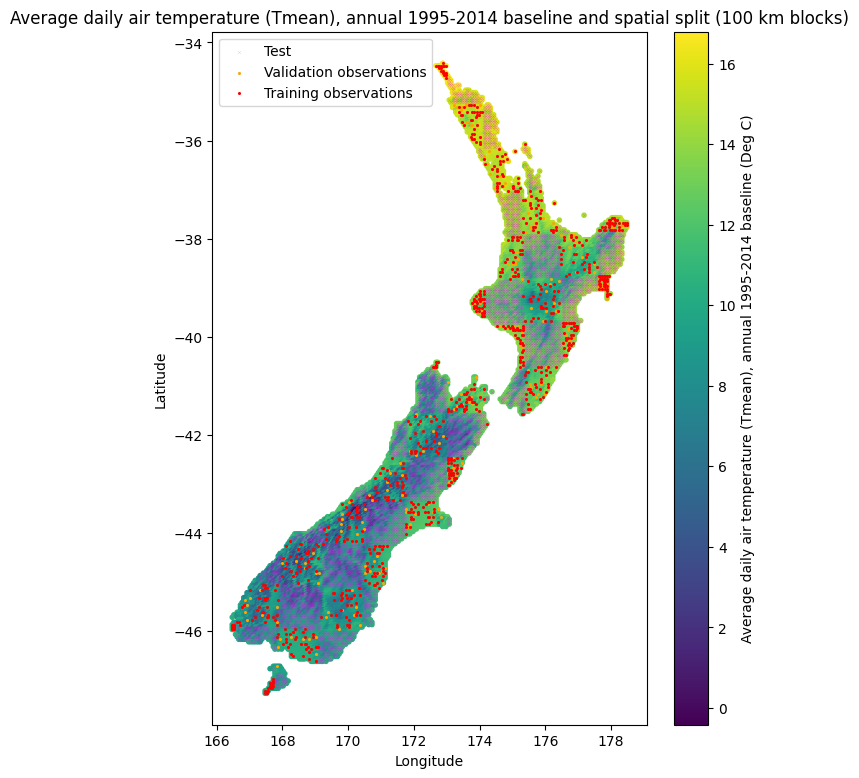

In [11]:
train_idx, test_idx, labeled_train_idx, labeled_val_idx, block_id = prepare_split(100)
plot_split(test_idx, labeled_train_idx, labeled_val_idx, 100)

In [12]:
print(f"Train-region points: {len(train_idx):,} ({len(train_idx)/len(climate_df):.1%})")
print(f"Test points:         {len(test_idx):,} ({len(test_idx)/len(climate_df):.1%})")

Train-region points: 5,830 (50.7%)
Test points:         5,661 (49.3%)


In [13]:
print(TARGET_NAME)
print("Train mean:", climate_df.loc[train_idx, "target"].mean())
print("Test mean: ", climate_df.loc[test_idx, "target"].mean())

print("\nTarget range")
print("Train:", climate_df.loc[train_idx, "target"].min(),
                climate_df.loc[train_idx, "target"].max())
print("Test: ", climate_df.loc[test_idx, "target"].min(),
                climate_df.loc[test_idx, "target"].max())


Average daily air temperature (Tmean), annual 1995-2014 baseline
Train mean: 10.295971
Test mean:  10.548356

Target range
Train: -0.4149231016635895 16.791284561157227
Test:  0.7001587152481079 16.705896377563477


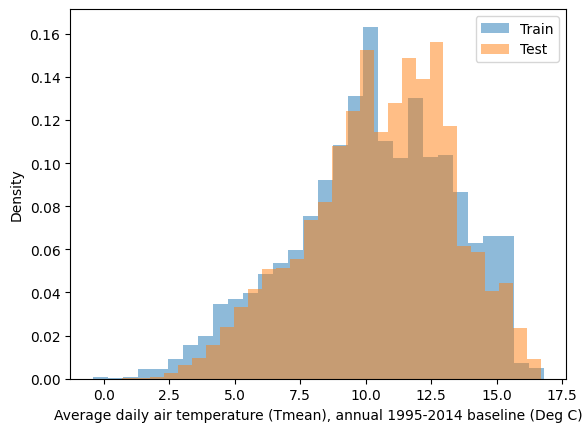

In [14]:
plt.hist(climate_df.loc[train_idx, "target"], bins=30,
         alpha=.5, density=True, label="Train")

plt.hist(climate_df.loc[test_idx, "target"], bins=30,
         alpha=.5, density=True, label="Test")

plt.xlabel(TARGET_LABEL)
plt.ylabel("Density")
plt.legend()
plt.show()


Do we see roughly similar distributions, or do we have a concerning distribution shift between train and test regions? For your assignment target, revisit this question rather than assuming the same split behaves the same way.

## 4. Baseline representations: raw coordinates and Random Fourier Features

Before using a pretrained foundation model, we need baselines.

### Baseline A: raw coordinates
A linear model using only longitude and latitude can learn a broad north–south or east–west gradient.

### Baseline B: Random Fourier Features (RFF)
RFF turns coordinates into many sinusoidal features at different spatial frequencies. It is a useful control because it is a richer spatial representation **without any pretrained Earth knowledge**.

If AlphaEarth/SLED/Tessera outperform RFF, the improvement is harder to dismiss as simply “the model had more dimensions.”


In [15]:
# Raw coordinate representation.
# Use WGS84 coordinates here so the coordinate-only baselines and pretrained
# coordinate encoders all receive the same coordinate reference system.
coords = climate_df[["lon", "lat"]].to_numpy(dtype=np.float32)

# Random Fourier Feature representation.
# Coordinates are put on a roughly 1000-km scale before applying random frequencies.
def make_rff(xy_m, n_features=128, length_scale_km=250, seed=42):
    assert n_features % 2 == 0
    rng = np.random.default_rng(seed)
    xy_km = xy_m / 1000.0
    W = rng.normal(
        loc=0.0,
        scale=1.0 / length_scale_km,
        size=(2, n_features // 2)
    )
    phase = rng.uniform(0, 2 * np.pi, size=(n_features // 2,))
    proj = xy_km @ W + phase
    return np.sqrt(2.0 / n_features) * np.concatenate([np.cos(proj), np.sin(proj)], axis=1)

rff = make_rff(xy_m, n_features=128, length_scale_km=250, seed=SEED).astype(np.float32)

embedding_sets = {
    "Raw coordinates": coords,
    "RFF-128": rff,
}

for name, X in embedding_sets.items():
    print(name, X.shape)


Raw coordinates (11491, 2)
RFF-128 (11491, 128)


## 5. SLED location embeddings

SLED (**Scalable Location Encoding via Distillation**) is especially convenient for this lab because inference requires only `(longitude, latitude)`.

The released package provides an RFF-based location encoder with 768-D output. We will compare the two currently released pretrained checkpoints:

- **SLED-S2-LS**: distilled from Sentinel-2 + Landsat teachers;
- **SLED-S1-S2-LS**: distilled from Sentinel-1 + Sentinel-2 + Landsat teachers.

Both are frozen. We are **not training SLED** here; we only ask SLED for a vector at each NZ climate-grid coordinate.

This is one reason coordinate networks / **implicit neural representations (INRs)** are interesting. Rather than storing a separate embedding for every location on Earth, learned geographic information is compressed into the network weights and queried continuously by coordinate. Once the small checkpoint is in memory, asking for a representation at a new longitude/latitude is extremely fast.

The next cell makes this concrete: change one longitude/latitude pair to any location you want and get its 768-D SLED representation immediately. After that we apply exactly the same operation to all NZ locations.

Official code: https://github.com/geohai/sled  
Released weights: https://huggingface.co/geohai

> Framework note: the few cells below use PyTorch because that is how SLED is released. The regression probe remains TensorFlow/Keras.


In [16]:
# Install the released SLED package and Hugging Face helper.
# In Colab, run this once per fresh runtime.
%pip -q install sled_geo huggingface_hub


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 81.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 9.6 MB/s eta 0:00:00
   ━━━━

In [17]:
import torch
from sled_geo import get_encoder

# GPU support is left here for convenience, but CPU is completely adequate for this lab.
TORCH_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Feature-extraction device:", TORCH_DEVICE)

# SLED and SatCLIP expect WGS84 coordinates in (longitude, latitude) order.
coords_lonlat = climate_df[["lon", "lat"]].to_numpy(dtype=np.float32)


def _load_sled_model(repo_id, device=TORCH_DEVICE):
    """Load a released 768-D RFF SLED encoder."""
    base = get_encoder.get_rff_encoder(embed_dim=768)
    loaded = base.from_pretrained(repo_id)
    model = loaded if isinstance(loaded, torch.nn.Module) else base
    return model.to(device).eval()


def _encode_locations_torch(model, lonlat, batch_size=2048, dtype=torch.float32):
    pieces = []
    with torch.inference_mode():
        for start in range(0, len(lonlat), batch_size):
            batch = torch.as_tensor(
                lonlat[start:start + batch_size],
                dtype=dtype,
                device=TORCH_DEVICE,
            )
            z = model(batch)
            if isinstance(z, (tuple, list)):
                z = z[0]
            pieces.append(z.detach().float().cpu().numpy())
    return np.concatenate(pieces, axis=0).astype(np.float32)


def get_sled_embeddings(repo_id, cache_path, model=None):
    """Generate once, then reuse a local .npz cache tied to the same rows and WGS84 coordinates."""
    cache_path = Path(cache_path)
    if cache_path.exists():
        data = np.load(cache_path, allow_pickle=False)
        row_id = data["row_id"].astype(int)
        X = data["embeddings"].astype(np.float32)

        cache_matches = (
            np.array_equal(row_id, climate_df["row_id"].to_numpy())
            and "lon" in data.files
            and "lat" in data.files
            and np.allclose(data["lon"], coords_lonlat[:, 0], atol=1e-6)
            and np.allclose(data["lat"], coords_lonlat[:, 1], atol=1e-6)
        )
        if cache_matches:
            print(f"Loaded cache {cache_path}: {X.shape}")
            return X
        print(f"Ignoring {cache_path}: rows/coordinates do not match this notebook version.")

    owns_model = model is None
    if model is None:
        print("Loading", repo_id)
        model = _load_sled_model(repo_id)

    X = _encode_locations_torch(model, coords_lonlat)
    np.savez_compressed(
        cache_path,
        row_id=climate_df["row_id"].to_numpy(),
        lon=coords_lonlat[:, 0],
        lat=coords_lonlat[:, 1],
        embeddings=X,
    )
    print(f"Saved cache {cache_path}: {X.shape}")

    if owns_model:
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return X


Feature-extraction device: cuda


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### Query SLED at one arbitrary location

Before generating thousands of NZ embeddings, try SLED as a continuous coordinate function. Change `EXAMPLE_LON` and `EXAMPLE_LAT` to any WGS84 location. There is no raster lookup or nearest-neighbour search here: once the checkpoint is loaded, the coordinate goes directly through the learned network and returns a 768-D representation.


In [18]:
# Try any WGS84 longitude/latitude here.
EXAMPLE_LON = 174.7772
EXAMPLE_LAT = -41.2889  # Wellington

# Load this checkpoint once; we reuse the same model for the full NZ grid in the next cell.
sled_s2_ls_model = _load_sled_model("geohai/sled-s2-ls")
example_lonlat = np.array([[EXAMPLE_LON, EXAMPLE_LAT]], dtype=np.float32)
example_embedding = _encode_locations_torch(sled_s2_ls_model, example_lonlat, batch_size=1)

print("Input lon/lat:", example_lonlat[0])
print("Embedding shape:", example_embedding.shape)
print("First 10 embedding values:", np.round(example_embedding[0, :10], 4))


config.json:   0%|          | 0.00/89.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 56.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Input lon/lat: [174.7772 -41.2889]
Embedding shape: (1, 768)
First 10 embedding values: [ 0.9803  0.3208 -0.8026  0.3709 -0.8887  0.907  -0.8444 -0.1109  0.622
 -1.1481]


In [19]:
# Generate both released SLED variants (one uses S2 + Landsat, the other S1 + S2 + Landsat).
# Reuse the S2+Landsat model we just queried above so it does not need to load twice.
X_sled_s2_ls = get_sled_embeddings(
    "geohai/sled-s2-ls",
    "nz_sled_s2_ls.npz",
    model=sled_s2_ls_model,
)
embedding_sets["SLED-S2-LS"] = X_sled_s2_ls

del sled_s2_ls_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

X_sled_s1_s2_ls = get_sled_embeddings(
    "geohai/sled-s1-s2-ls",
    "nz_sled_s1_s2_ls.npz",
)
embedding_sets["SLED-S1-S2-LS"] = X_sled_s1_s2_ls

for name in ["SLED-S2-LS", "SLED-S1-S2-LS"]:
    X = embedding_sets[name]
    print(f"{name:20s} -> {X.shape}")


Saved cache nz_sled_s2_ls.npz: (11491, 768)
Loading geohai/sled-s1-s2-ls


config.json:   0%|          | 0.00/89.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 56.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Saved cache nz_sled_s1_s2_ls.npz: (11491, 768)
SLED-S2-LS           -> (11491, 768)
SLED-S1-S2-LS        -> (11491, 768)


### Think before probing

SLED's output dimension (768) is much larger than raw coordinates (2) or our RFF baseline (128). Therefore, **SLED beating raw coordinates is not by itself enough evidence that distillation helped**.

The RFF comparison matters because both RFF and SLED start from coordinates and both are high-dimensional. The key difference is that SLED's representation has been shaped by EO teacher embeddings during pretraining.

### Question 2

Before seeing downstream scores, predict which SLED variant you expect to work better for our in-class temperature target. When you later switch to rainfall, wind, humidity, or an extreme indicator, should the same variant necessarily remain better? Does adding more pretraining modalities have to improve every downstream variable?


## 6. SatCLIP location embeddings

SatCLIP is another coordinate-only location encoder, but it was trained contrastively rather than through SLED's MSE-style distillation framework. The official repository provides a lightweight loader that reconstructs **only the location encoder** from a pretrained checkpoint, so we do not need the satellite-image tower.

We use **ViT16-L40**, which produces a 512-D location embedding. I include it in the main comparison so we can contrast SLED's distillation objective with SatCLIP's contrastive objective. If somehow SatCLIP fails to load, you may temporarily set `RUN_SATCLIP = False`; the rest of the notebook will still run.

Official implementation: https://github.com/microsoft/satclip


In [20]:
%pip -q install huggingface_hub einops

RUN_SATCLIP = True

if RUN_SATCLIP:
    import sys
    import subprocess
    from huggingface_hub import hf_hub_download

    SATCLIP_REPO = Path("satclip_repo")
    if not SATCLIP_REPO.exists():
        subprocess.run(
            ["git", "clone", "-q", "--depth", "1", "https://github.com/microsoft/satclip.git", str(SATCLIP_REPO)],
            check=True,
        )

    satclip_module_path = str((SATCLIP_REPO / "satclip").resolve())
    if satclip_module_path not in sys.path:
        sys.path.insert(0, satclip_module_path)

    from load_lightweight import get_satclip_loc_encoder

    satclip_ckpt = hf_hub_download(
        repo_id="microsoft/SatCLIP-ViT16-L40",
        filename="satclip-vit16-l40.ckpt",
    )
    satclip_model = get_satclip_loc_encoder(satclip_ckpt, TORCH_DEVICE).to(TORCH_DEVICE).eval()

    X_satclip = _encode_locations_torch(
        satclip_model,
        coords_lonlat,
        batch_size=2048,
        dtype=torch.float64,
    )
    embedding_sets["SatCLIP-ViT16-L40"] = X_satclip
    print("SatCLIP-ViT16-L40 ->", X_satclip.shape)
else:
    print("SatCLIP skipped. Set RUN_SATCLIP=True to include it.")


satclip-vit16-l40.ckpt: reconstructing file:   0%|          |  0.00B /  121MB            

satclip-vit16-l40.ckpt: downloading bytes:           |  0.00B            

SatCLIP-ViT16-L40 -> (11491, 256)


## 7. AlphaEarth Foundations embeddings + elevation

Google's **Satellite Embedding V1** dataset provides a 64-dimensional annual embedding field produced by AlphaEarth Foundations from multiple Earth-observation sources.

Unlike SLED and SatCLIP, AlphaEarth is **not a coordinate-only encoder**. Each vector is derived from EO observations at that location. This makes the comparison conceptually interesting rather than simply a leaderboard comparison.

For this class, I provide:

```text
nz_alphaearth_2024.npz
```

The file contains:

- `row_id`: the climate-grid identifier;
- `alphaearth`: an `(N, 64)` matrix;
- `elevation_m`: elevation in metres for the same locations.

We load elevation from the same bundle so we can use it as a conventional ancillary baseline throughout the rest of the notebook.

Documentation:  
https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL


In [21]:
ALPHAEARTH_PATH = "nz_alphaearth_2024.npz"
USE_ALPHAEARTH = True

# Shared class file. If you are running locally and the file is beside the notebook,
# fetch_drive_file() will simply use the local copy.
ALPHAEARTH_DRIVE_LINK = "https://drive.google.com/file/d/1BlgfNQdy3_DAd2qABo7Rbd3EOOC19HfB/view?usp=sharing"


In [22]:
def ensure_alphaearth_file(path=ALPHAEARTH_PATH, drive_link=ALPHAEARTH_DRIVE_LINK):
    """Use a local/cached file, otherwise read the class file from my Google Drive."""
    return fetch_drive_file(drive_link, path)


In [23]:
def load_precomputed_alphaearth(path):
    data = np.load(path, allow_pickle=False)

    row_id_all = data["row_id"].astype(int)
    X_all = data["alphaearth"].astype(np.float32)

    # Subset/reorder by row_id so the same AlphaEarth file works for alternative targets
    # that use the same NZ grid but may contain a different set/order of valid cells.
    lookup = {rid: i for i, rid in enumerate(row_id_all)}
    requested = climate_df["row_id"].to_numpy(dtype=int)
    missing = [rid for rid in requested if rid not in lookup]
    if missing:
        raise ValueError(
            f"AlphaEarth bundle is missing {len(missing)} row IDs needed by this target."
        )

    take = np.array([lookup[rid] for rid in requested], dtype=int)
    X = X_all[take]

    if "elevation_m" not in data.files:
        raise ValueError(
            "nz_alphaearth_2024.npz must contain elevation_m for the ancillary-variable experiments."
        )
    elevation = data["elevation_m"].astype(np.float32)[take]

    return X, elevation


In [24]:
if USE_ALPHAEARTH:
    alphaearth_file = ensure_alphaearth_file(path=ALPHAEARTH_PATH)
    X_alphaearth, elevation_m = load_precomputed_alphaearth(alphaearth_file)
    embedding_sets["AlphaEarth-64"] = X_alphaearth

    print("Loaded AlphaEarth:", X_alphaearth.shape)
    print("Loaded elevation:", elevation_m.shape)
else:
    raise RuntimeError("AlphaEarth is part of the core lab; keep USE_ALPHAEARTH=True for the class workflow.")


Loaded from my Google Drive: nz_alphaearth_2024.npz
Loaded AlphaEarth: (11491, 64)
Loaded elevation: (11491,)


### Already done: generating `nz_alphaearth_2024.npz` with Earth Engine

You do **not** need to run the next two cells for the lab. I have already sampled AlphaEarth and elevation and provide the resulting `.npz` file through Google Drive. I am keeping the code here only so the data-preparation step is reproducible.


In [25]:
# Already done for the class dataset. Leave False during the lab.
GENERATE_ALPHAEARTH_WITH_EE = False
EE_PROJECT = "verdant-catcher-509419-q4"

if GENERATE_ALPHAEARTH_WITH_EE:
    import ee
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    print("Earth Engine initialized.")
else:
    print("Skipping Earth Engine generation; using the class .npz file.")


Skipping Earth Engine generation; using the class .npz file.


In [26]:
# Reproducibility only: sample AlphaEarth + SRTM elevation at the climate-grid points.
# Earth Engine expects WGS84, so use the WGS84 lon/lat columns.
# This is NOT part of the student workflow.

def sample_alphaearth_at_points(df, year=2024, chunk_size=400):
    import ee

    start = f"{year}-01-01"
    end = f"{year + 1}-01-01"

    aef = (
        ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
        .filterDate(start, end)
        .mosaic()
    )
    emb_bands = [f"A{i:02d}" for i in range(64)]

    elevation = ee.Image("USGS/SRTMGL1_003").select("elevation").rename("elevation_m")
    stack = aef.select(emb_bands).addBands(elevation)

    rows = []
    for start_i in range(0, len(df), chunk_size):
        chunk = df.iloc[start_i:start_i + chunk_size]
        features = [
            ee.Feature(
                ee.Geometry.Point([float(r.lon), float(r.lat)]),
                {"row_id": int(r.row_id)}
            )
            for r in chunk.itertuples(index=False)
        ]
        fc = ee.FeatureCollection(features)
        sampled = stack.sampleRegions(
            collection=fc,
            properties=["row_id"],
            scale=10,
            geometries=False,
            tileScale=4,
        )
        info = sampled.getInfo()["features"]
        rows.extend([f["properties"] for f in info])
        print(f"Sampled {min(start_i + chunk_size, len(df)):,} / {len(df):,}")

    out = pd.DataFrame(rows).sort_values("row_id").reset_index(drop=True)
    return out, emb_bands


if GENERATE_ALPHAEARTH_WITH_EE:
    aef_df, AEF_BANDS = sample_alphaearth_at_points(climate_df, year=2024)
    assert len(aef_df) == len(climate_df), "Some locations were not returned by Earth Engine."
    assert np.array_equal(aef_df["row_id"].to_numpy(), climate_df["row_id"].to_numpy())

    X_alphaearth_generated = aef_df[AEF_BANDS].to_numpy(dtype=np.float32)
    elevation_generated = aef_df["elevation_m"].to_numpy(dtype=np.float32)

    out_path = Path("nz_alphaearth_2024.npz")
    np.savez_compressed(
        str(out_path),
        row_id=climate_df["row_id"].to_numpy(),
        lon=climate_df["lon"].to_numpy(dtype=np.float32),
        lat=climate_df["lat"].to_numpy(dtype=np.float32),
        alphaearth=X_alphaearth_generated,
        elevation_m=elevation_generated,
    )
    print("Saved:", out_path)


**Let's visualize the embeddings and compare!!!**

### Visualizing the spatial structure of the embeddings

Each embedding contains many dimensions, so we cannot visualize the full representation directly. Here we use **Principal Component Analysis (PCA)** to compress each embedding to three dimensions and display those three components as red, green, and blue.

A few points are important when interpreting these maps:

- PCA is performed **separately for each representation**. Therefore, a particular color does not have the same meaning across AlphaEarth, SLED, and SatCLIP.
- The colors are **not physical variables** such as temperature, vegetation, or elevation. They simply provide a way to visualize similarities and differences within each embedding space.
- **AlphaEarth is derived from local Earth-observation imagery**, so neighbouring locations can have substantially different embeddings because of differences in vegetation, land cover, terrain, water, agriculture, and other surface characteristics. We therefore expect considerably more fine-scale spatial texture.
- **SLED and SatCLIP are location encoders**: their embeddings are generated as a continuous function of longitude and latitude. Their spatial patterns are consequently much smoother.

Notice the difference between a representation that responds to the locally observed Earth surface and representations that encode geographic location continuously.

Because our climate locations lie on a regular grid, we display each location as a grid cell rather than as a circular plotting symbol. This preserves the fine spatial detail in AlphaEarth without visually overcrowding the map.

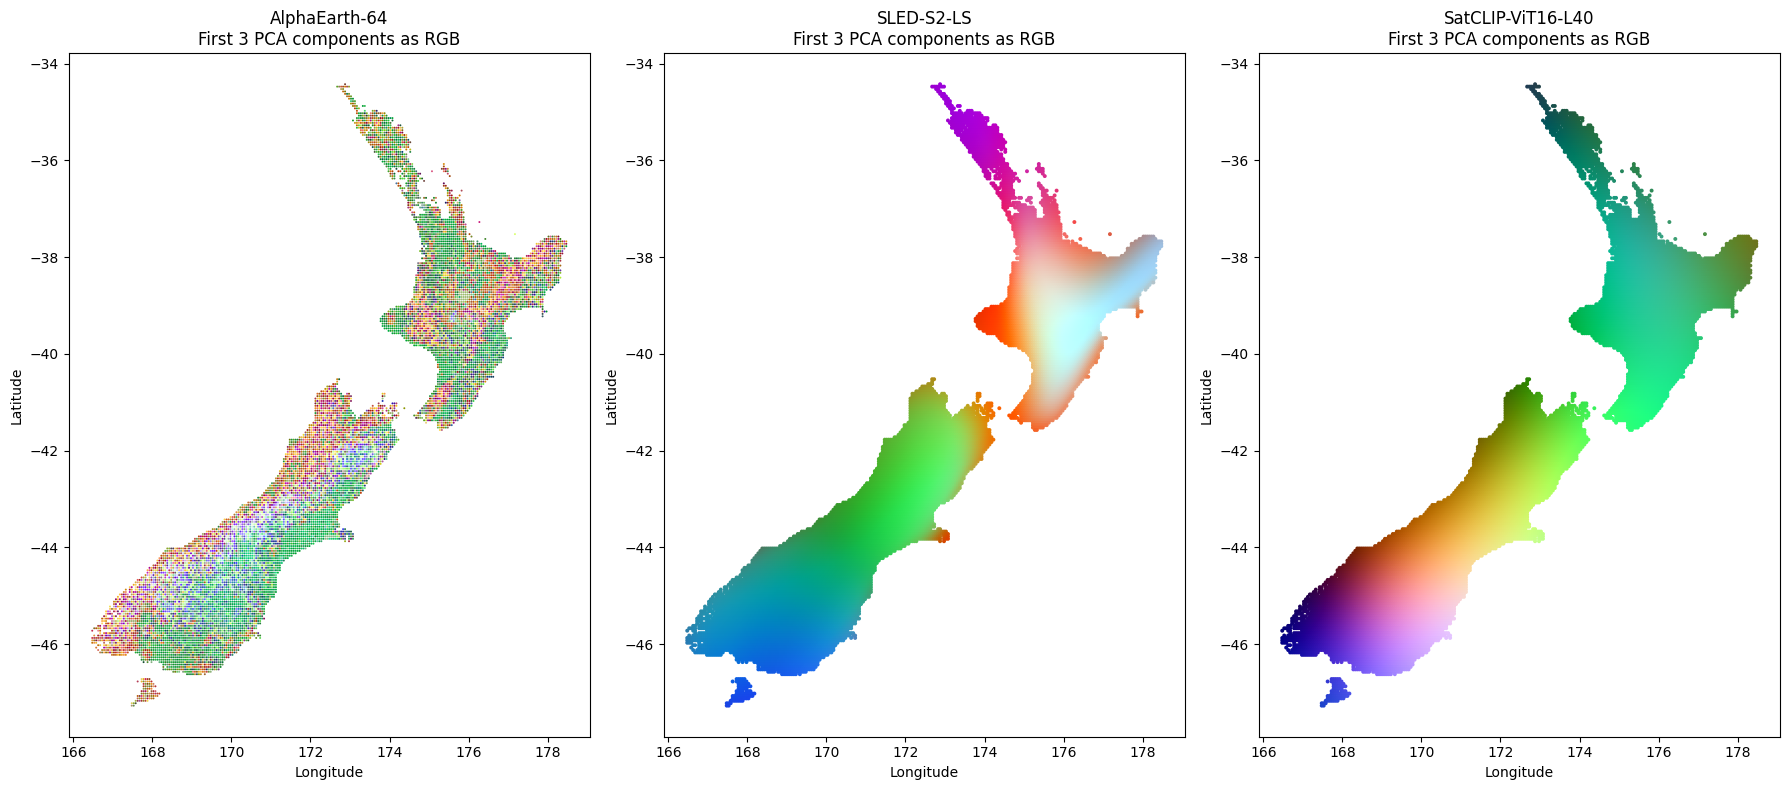

In [27]:
# Visualize AlphaEarth, SLED, and SatCLIP in the same way.
# PCA compresses each embedding to three components, displayed as RGB.

from sklearn.decomposition import PCA

VIS_REPS = [
    "AlphaEarth-64",
    "SLED-S2-LS",
    "SatCLIP-ViT16-L40",
]

VIS_REPS = [name for name in VIS_REPS if name in embedding_sets]

fig, axes = plt.subplots(1, len(VIS_REPS), figsize=(6 * len(VIS_REPS), 8))

for ax, name in zip(axes, VIS_REPS):
    X = embedding_sets[name]

    rgb_dims = PCA(n_components=3, random_state=SEED).fit_transform(X)

    lo = np.percentile(rgb_dims, 2, axis=0)
    hi = np.percentile(rgb_dims, 98, axis=0)
    rgb = np.clip((rgb_dims - lo) / (hi - lo + 1e-8), 0, 1)

    # Smaller points for AlphaEarth because it contains much more fine-scale texture.
    point_size = 2 if name == "AlphaEarth-64" else 8

    ax.scatter(
        climate_df["lon"],
        climate_df["lat"],
        c=rgb,
        s=point_size,
        linewidths=0,
        rasterized=True
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"{name}\nFirst 3 PCA components as RGB")

plt.tight_layout()
plt.show()

### Looking at one embedding direction at a time

The RGB maps above are useful for seeing the overall spatial structure of each representation, but combining three PCA components into color can make interpretation difficult.

Here we therefore plot only the **first principal component (PC1)** of each embedding.

PC1 is the single direction in the embedding space that explains the greatest amount of variation across our New Zealand locations. It is still **not a physical climate or environmental variable**, and PC1 from one representation should not be interpreted as equivalent to PC1 from another representation.

Instead, compare the **spatial character** of the maps:

- Does the representation change gradually over large distances?
- Does it contain sharp local boundaries?
- Is there substantial fine-scale variation?
- Does the representation distinguish locations that are geographically close to one another?

You should expect AlphaEarth to retain considerably more local spatial structure because it is derived from Earth observations. SLED and SatCLIP are generated from geographic coordinates and are therefore likely to show smoother spatial organization.

These differences do not by themselves tell us which embedding is more useful for our climate task. We will test that quantitatively with the downstream prediction experiments.

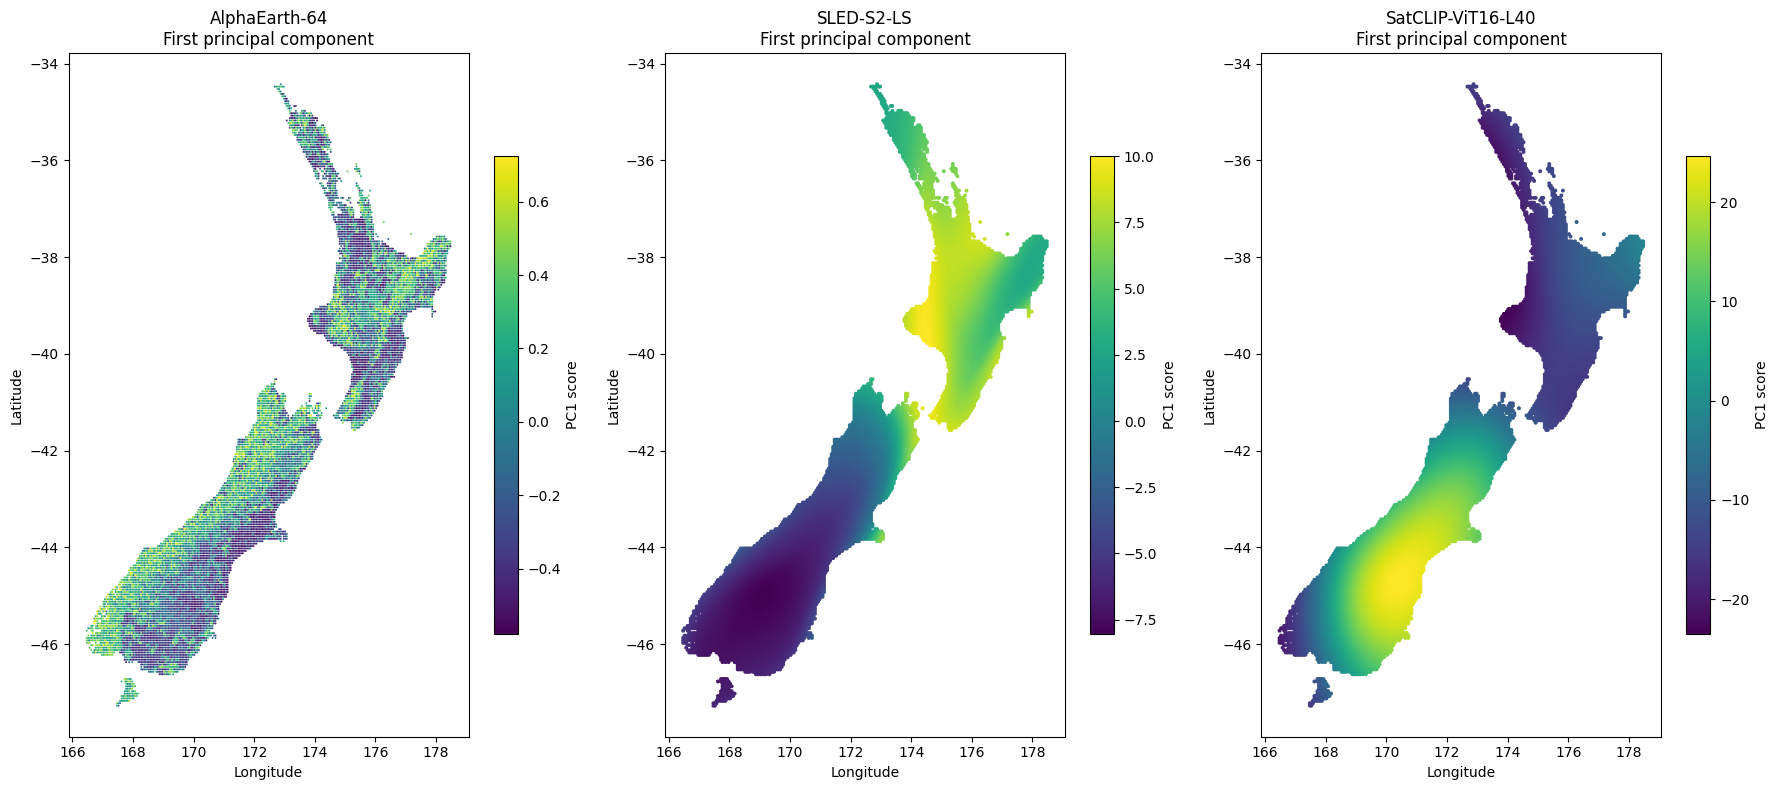

In [28]:
# Plot the first principal component of each embedding.

fig, axes = plt.subplots(1, len(VIS_REPS), figsize=(6 * len(VIS_REPS), 8))

for ax, name in zip(axes, VIS_REPS):
    X = embedding_sets[name]

    pc1 = PCA(n_components=1, random_state=SEED).fit_transform(X).ravel()

    point_size = 2 if name == "AlphaEarth-64" else 8

    sc = ax.scatter(
        climate_df["lon"],
        climate_df["lat"],
        c=pc1,
        s=point_size,
        cmap="viridis",
        linewidths=0,
        rasterized=True
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"{name}\nFirst principal component")

    plt.colorbar(sc, ax=ax, shrink=0.7, label="PC1 score")

plt.tight_layout()
plt.show()

Let's show PC1 only:

### Embedding visualization question

Each panel compresses a high-dimensional learned representation into three PCA components, so the colors are only a visualization aid.

- Which representations show similar large-scale spatial organization?
- Which show finer local structure?
- What kinds of Earth-surface properties might be indirectly represented?
- Why should we **not** call an individual color/component a physical variable such as vegetation, moisture, or elevation?
- Compared with SLED and SatCLIP, what extra information can AlphaEarth use at prediction time?


## 8. Elevation as an ancillary baseline

We will use a conventional ancillary variable, **elevation**, similar to how we use other predictors for any downstream task, or an observation to enhance embeddings. Or differently, for a certain place with a certain elevation, what's target value there, given 'what's there'? The 'what's there' comes from the embeddings.

This gives us three directly interpretable model inputs for each main embedding:

1. **elevation only -> target**
2. **embedding only -> target**
3. **embedding + elevation -> target**

The elevation-only model is important. Without it, we could see an improvement after adding elevation to an embedding but still not know whether the embedding itself adds much beyond topography.

Later, you may add more ancillary variables, direct satellite observations, or field observations if they are scientifically sensible for your assignment target.


In [29]:
y = climate_df["target"].to_numpy(dtype=np.float32)
elevation_m = np.asarray(elevation_m, dtype=np.float32)

if len(elevation_m) != len(climate_df):
    raise ValueError("Elevation must have one value for every target location.")
if not np.isfinite(elevation_m).all():
    raise ValueError("Elevation contains missing/non-finite values.")

X_elevation = elevation_m[:, None]

print("Elevation range (m):", float(elevation_m.min()), "to", float(elevation_m.max()))
print("Elevation feature matrix:", X_elevation.shape)


Elevation range (m): -1.0 to 2556.0
Elevation feature matrix: (11491, 1)


## 9. TensorFlow linear probe

This is the main downstream model.

Notice how much simpler it is than the  CNN we built the other week.

```text
embedding -> normalization -> Dense(1)
```

There are **no hidden nonlinear layers**. The representation is frozen. Only the final linear mapping is learned.

We use the same model family, optimizer, stopping rule, and train/validation/test locations for every representation.


In [30]:
def fit_linear_probe(X_train, y_train, X_val, y_val, l2=1e-4, verbose=0):
    """Train a one-layer TensorFlow/Keras regression probe."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    normalizer = layers.Normalization(axis=-1)
    normalizer.adapt(X_train)

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        normalizer,
        layers.Dense(
            1,
            activation="linear",
            kernel_regularizer=keras.regularizers.l2(l2)
        )
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-2),
        loss="mse",
        metrics=[keras.metrics.RootMeanSquaredError(name="rmse")]
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=300,
        batch_size=64,
        callbacks=[early_stop],
        verbose=verbose
    )
    return model, history


def regression_metrics(y_true, y_pred):
    y_pred = np.asarray(y_pred).reshape(-1)
    return {
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


In [31]:
# Inspect the architecture using one SLED probe.
# AlphaEarth is evaluated with the SAME TensorFlow model in the next section.
PRIMARY_REP = "SLED-S2-LS"
X_primary = embedding_sets[PRIMARY_REP]

model_primary, history_primary = fit_linear_probe(
    X_primary[labeled_train_idx], y[labeled_train_idx],
    X_primary[labeled_val_idx], y[labeled_val_idx]
)

print("Primary representation used for model inspection:", PRIMARY_REP, X_primary.shape)
model_primary.summary()


Primary representation used for model inspection: SLED-S2-LS (11491, 768)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 768)            │         1,537 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,846 (15.03 KB)

 Trainable params: 769 (3.00 KB)

 Non-trainable params: 1,537 (6.01 KB)

 Optimizer params: 1,540 (6.02 KB)

In [32]:
history_df = pd.DataFrame(history_primary.history)
history_df.tail(200)


,loss,rmse,val_loss,val_rmse
91,9.584139,3.095747,9.008410,3.001319
92,9.283292,3.046769,8.717127,2.952394
93,8.993130,2.998772,8.435917,2.904379
94,8.713356,2.951755,8.164484,2.857268
95,8.443647,2.905709,7.902556,2.811059
...,...,...,...,...
286,1.582953,1.257464,1.969337,1.402710
287,1.583352,1.257619,1.969851,1.402889
288,1.583768,1.257780,1.970380,1.403074
289,1.584198,1.257946,1.970923,1.403264


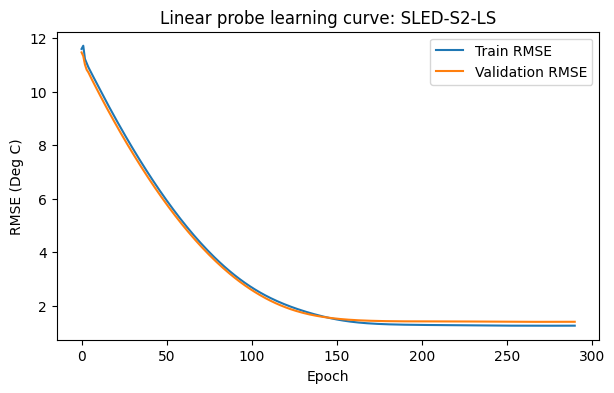

In [33]:
plt.figure(figsize=(7, 4))
plt.plot(history_primary.history["rmse"], label="Train RMSE")
plt.plot(history_primary.history["val_rmse"], label="Validation RMSE")
plt.xlabel("Epoch")
plt.ylabel(f"RMSE ({TARGET_UNITS})" if TARGET_UNITS else "RMSE")
plt.title(f"Linear probe learning curve: {PRIMARY_REP}")
plt.legend()
plt.show()


## 10. Controlled representation comparison

Now we run **exactly the same TensorFlow probe** on every representation in `embedding_sets`.

The required comparison is:

- raw coordinates;
- untrained RFF;
- SLED-S2-LS;
- SLED-S1-S2-LS;
- **AlphaEarth-64**.

SatCLIP is added automatically if you enabled it.

Because the probe, training labels, validation set, and spatial test blocks are held fixed, differences are attributable to the information made linearly available by each frozen representation—not to a different downstream model.


In [34]:
def evaluate_representation(name, X):
    model, history = fit_linear_probe(
        X[labeled_train_idx], y[labeled_train_idx],
        X[labeled_val_idx], y[labeled_val_idx]
    )
    pred = model.predict(X[test_idx], verbose=0).reshape(-1)
    metrics = regression_metrics(y[test_idx], pred)
    metrics["Representation"] = name
    metrics["Features"] = X.shape[1]
    return model, pred, metrics

results = []
models = {}
test_predictions = {}

for name, X in embedding_sets.items():
    model, pred, metrics = evaluate_representation(name, X)
    models[name] = model
    test_predictions[name] = pred
    results.append(metrics)

results_df = pd.DataFrame(results)[["Representation", "Features", "RMSE", "MAE", "R2"]]
results_df.sort_values("RMSE")


,Representation,Features,RMSE,MAE,R2
5,AlphaEarth-64,64,0.754331,0.592919,0.925706
3,SLED-S1-S2-LS,768,1.602957,1.182781,0.664517
4,SatCLIP-ViT16-L40,256,1.612063,1.237144,0.660694
2,SLED-S2-LS,768,1.626889,1.201133,0.654424
1,RFF-128,128,1.779096,1.310003,0.586737
0,Raw coordinates,2,1.925077,1.490092,0.516136


### Question 3

Do not just report the row with the lowest RMSE.

- Does SLED beat raw coordinates?
- More importantly, does SLED beat the **untrained RFF** representation?
- How does **AlphaEarth** compare with SLED?
- Remember that AlphaEarth sees local EO information at prediction time, while SLED receives only coordinates. Is this an apples-to-apples comparison?
- Do the S2+Landsat and S1+S2+Landsat SLED models behave differently?
- If SatCLIP is enabled, how does contrastive pretraining compare with SLED's distillation approach?
- Why is embedding dimensionality a potential confound?
- How might the answer change if you used only 100 labels instead of 800?


## 11. Final comparison: embeddings, elevation, and embeddings + elevation

Now we make the comparison that matters most for this lab.

First fit an **elevation-only** baseline. Then, for AlphaEarth, both SLED variants, and SatCLIP, compare:

- embedding only;
- embedding + elevation.

Everything else stays fixed: the same labelled training locations, validation locations, spatial test blocks, TensorFlow linear probe, optimizer, and stopping rule.

1. **Does the embedding add information beyond elevation?**
2. **Does explicit elevation add information beyond the embedding?**
3. Does adding an observation (such as elevation) to embedding drastically level tye plaing field for embeddings of different technologies?



In [35]:
def evaluate_feature_set(rep_name, input_name, X):
    model, _ = fit_linear_probe(
        X[labeled_train_idx], y[labeled_train_idx],
        X[labeled_val_idx], y[labeled_val_idx]
    )
    pred = model.predict(X[test_idx], verbose=0).reshape(-1)
    metrics = regression_metrics(y[test_idx], pred)
    metrics.update({
        "Representation": rep_name,
        "Input": input_name,
        "Features": X.shape[1],
    })
    return model, pred, metrics


final_rows = []
final_models = {}
final_predictions = {}

# One common ancillary baseline.
model, pred, metrics = evaluate_feature_set(
    "Ancillary baseline", "elevation only", X_elevation
)
final_rows.append(metrics)
final_models[("Ancillary baseline", "elevation only")] = model

FINAL_REPS = [
    "SLED-S2-LS",
    "SLED-S1-S2-LS",

    "AlphaEarth-64",
]
FINAL_REPS += [name for name in embedding_sets if name.startswith("SatCLIP")]
FINAL_REPS = [name for name in FINAL_REPS if name in embedding_sets]

for rep_name in FINAL_REPS:
    X = embedding_sets[rep_name].astype(np.float32)
    X_plus_elev = np.column_stack([X, elevation_m]).astype(np.float32)

    final_predictions[rep_name] = {}

    for input_name, X_features in [
        ("embedding only", X),
        ("embedding + elevation", X_plus_elev),
    ]:
        model, pred, metrics = evaluate_feature_set(rep_name, input_name, X_features)
        final_rows.append(metrics)
        final_models[(rep_name, input_name)] = model
        final_predictions[rep_name][input_name] = pred

final_df = pd.DataFrame(final_rows)[
    ["Representation", "Input", "Features", "RMSE", "MAE", "R2"]
]
final_df.sort_values(["Representation", "Input"]).reset_index(drop=True)


,Representation,Input,Features,RMSE,MAE,R2
0,AlphaEarth-64,embedding + elevation,65,0.655716,0.516665,0.943862
1,AlphaEarth-64,embedding only,64,0.754331,0.592919,0.925706
2,Ancillary baseline,elevation only,1,1.495909,1.201335,0.707829
3,SLED-S1-S2-LS,embedding + elevation,769,0.530114,0.373473,0.963308
4,SLED-S1-S2-LS,embedding only,768,1.602957,1.182781,0.664517
5,SLED-S2-LS,embedding + elevation,769,0.550759,0.392804,0.960395
6,SLED-S2-LS,embedding only,768,1.626889,1.201133,0.654424
7,SatCLIP-ViT16-L40,embedding + elevation,257,0.532628,0.380432,0.962960
8,SatCLIP-ViT16-L40,embedding only,256,1.612063,1.237144,0.660694


### Question 4

Let's think about interpretation.

For **SLED, SatCLIP, and AlphaEarth separately**:

- How does embedding-only performance compare with the **elevation-only** baseline?
- How much does adding explicit elevation change the embedding model?
- Does the embedding still add useful information beyond elevation?
- Does elevation affect the coordinate-only encoders and AlphaEarth in the same way?
- Where and if was elevation used in pretraining each of these representations? Was it used?
- If explicit elevation removes much of an embedding's advantage, what might that embedding have encoded implicitly?
- AlphaEarth uses local EO at inference time while SLED and SatCLIP use only coordinates. How should that change the way you interpret their scores?
- Why should we be cautious about interpreting predictive gains as evidence that an embedding has learned climate *physics*?


## 12. Error analysis: map the residuals

In our previous lab, we inspected misclassified image patches. For a continuous spatial task, the analogous error analysis is a **residual map**.

Here we compare the same embedding **with and without elevation**. Use the same residual color scale so that the two maps are visually comparable.


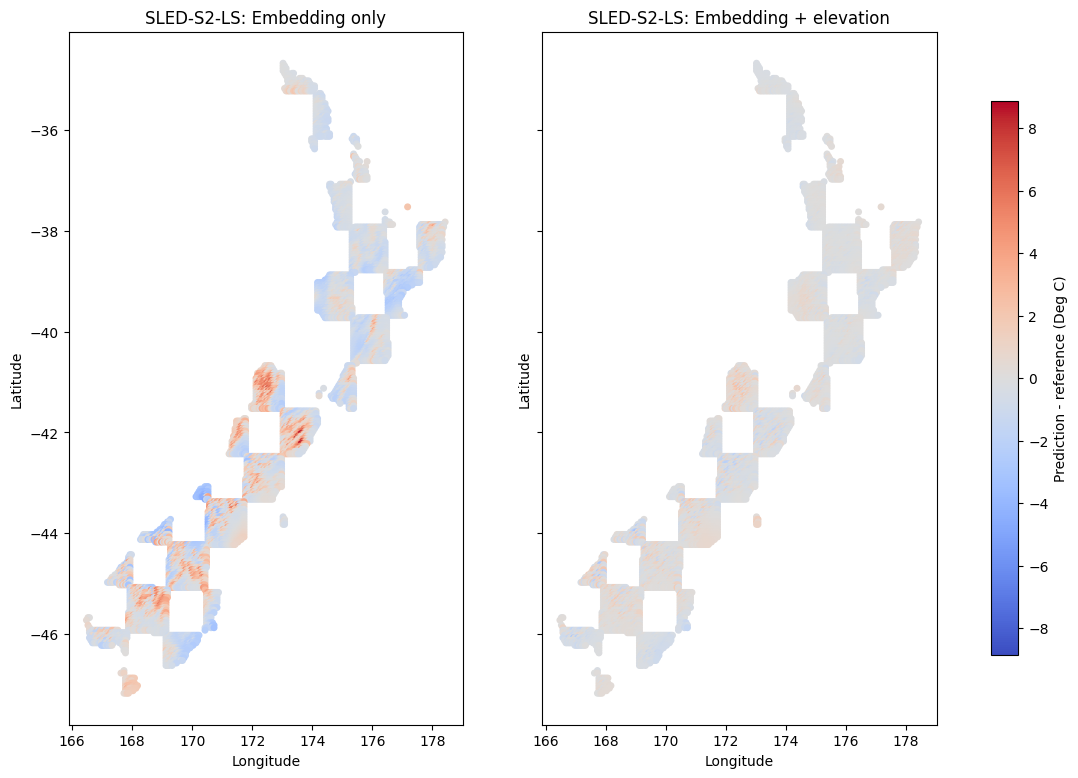

,Input,RMSE,MAE,R2
0,embedding only,1.626889,1.201133,0.654424
1,embedding + elevation,0.550759,0.392804,0.960395


In [36]:
MAP_REP = "SLED-S2-LS"  # try AlphaEarth-64 or SatCLIP-ViT16-L40 as well
if MAP_REP not in final_predictions:
    MAP_REP = list(final_predictions)[0]

true = y[test_idx]
pred_embedding = final_predictions[MAP_REP]["embedding only"]
pred_plus_elev = final_predictions[MAP_REP]["embedding + elevation"]

resid_embedding = pred_embedding - true
resid_plus_elev = pred_plus_elev - true
vmax = max(np.abs(resid_embedding).max(), np.abs(resid_plus_elev).max())

fig, axes = plt.subplots(1, 2, figsize=(14, 9), sharex=True, sharey=True)

for ax, residual, title in [
    (axes[0], resid_embedding, "Embedding only"),
    (axes[1], resid_plus_elev, "Embedding + elevation"),
]:
    sc = ax.scatter(
        climate_df.loc[test_idx, "lon"],
        climate_df.loc[test_idx, "lat"],
        c=residual,
        s=16,
        vmin=-vmax,
        vmax=vmax,
        cmap="coolwarm",
    )
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(f"{MAP_REP}: {title}")

residual_label = f"Prediction - reference ({TARGET_UNITS})" if TARGET_UNITS else "Prediction - reference"
fig.colorbar(sc, ax=axes, label=residual_label, shrink=0.8)
plt.show()

residual_metrics = pd.DataFrame([
    {"Input": "embedding only", **regression_metrics(true, pred_embedding)},
    {"Input": "embedding + elevation", **regression_metrics(true, pred_plus_elev)},
])
residual_metrics


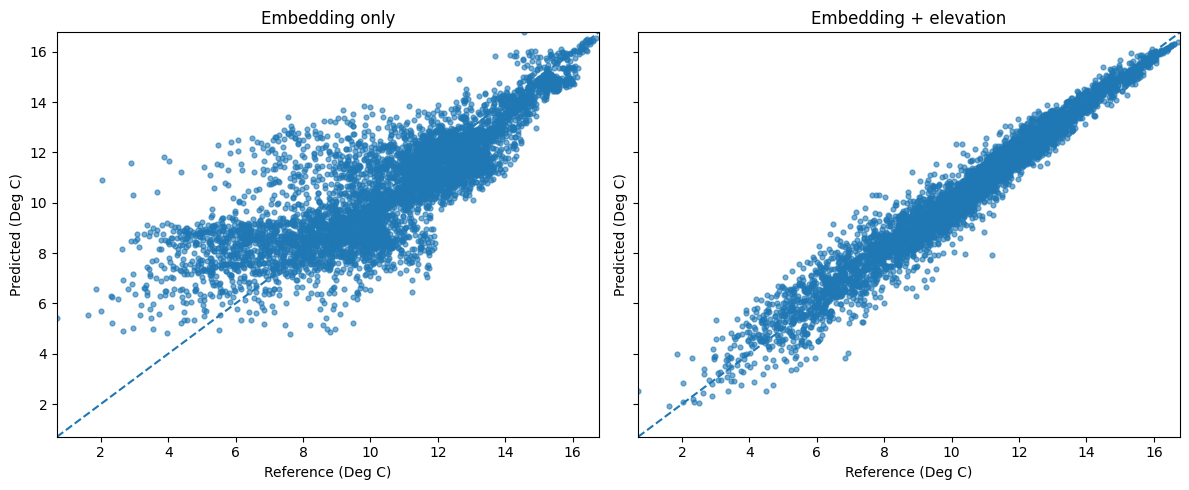

In [37]:
# Predicted versus reference values for the same two models.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lims = [
    min(true.min(), pred_embedding.min(), pred_plus_elev.min()),
    max(true.max(), pred_embedding.max(), pred_plus_elev.max()),
]

for ax, pred, title in [
    (axes[0], pred_embedding, "Embedding only"),
    (axes[1], pred_plus_elev, "Embedding + elevation"),
]:
    ax.scatter(true, pred, s=12, alpha=0.6)
    ax.plot(lims, lims, linestyle="--")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_xlabel(f"Reference ({TARGET_UNITS})" if TARGET_UNITS else "Reference")
    ax.set_ylabel(f"Predicted ({TARGET_UNITS})" if TARGET_UNITS else "Predicted")
    ax.set_title(title)

plt.tight_layout()
plt.show()


### Question 5

Look for **spatially coherent errors**, not just large errors.

- Where does adding elevation visibly reduce residual structure?
- Where does it make little difference?
- Are errors concentrated in mountainous areas, coasts, or particular islands/regions?
- What does a spatial cluster of residuals tell you that RMSE does not?
- What additional physical or observational variable would you add next for your target?


## 13. Sample efficiency

One promise of pretrained embeddings is that they should help when labels are scarce.

Repeat the experiment using **100, 250, and 800 labels**, while keeping the **same spatial test blocks and validation set**.

A useful final figure is:

> **test RMSE vs. number of labelled locations**

for raw coordinates, RFF, both SLED variants, AlphaEarth, and SatCLIP.

This comparison is particularly interesting because the representations use different information at inference time:

- SLED/SatCLIP: `(lon, lat)` only;
- AlphaEarth: EO-derived vector sampled at that location.

The figure therefore asks not only which representation performs well, but **how much sparse local climate supervision each representation needs**.


,Labels,Representation,RMSE,MAE,R2
0,100,Raw coordinates,5.848079,5.520550,-3.465333
5,100,SatCLIP-ViT16-L40,6.339309,5.962599,-4.247003
1,100,RFF-128,6.404265,6.089402,-4.355081
3,100,SLED-S1-S2-LS,6.511824,6.051871,-4.536469
2,100,SLED-S2-LS,6.539935,6.059240,-4.584372
4,100,AlphaEarth-64,6.826873,6.608430,-5.085147
10,250,AlphaEarth-64,2.696034,2.563015,0.050974
6,250,Raw coordinates,2.866879,2.556419,-0.073115
7,250,RFF-128,3.217587,2.871183,-0.351724
11,250,SatCLIP-ViT16-L40,3.314152,2.924429,-0.434076


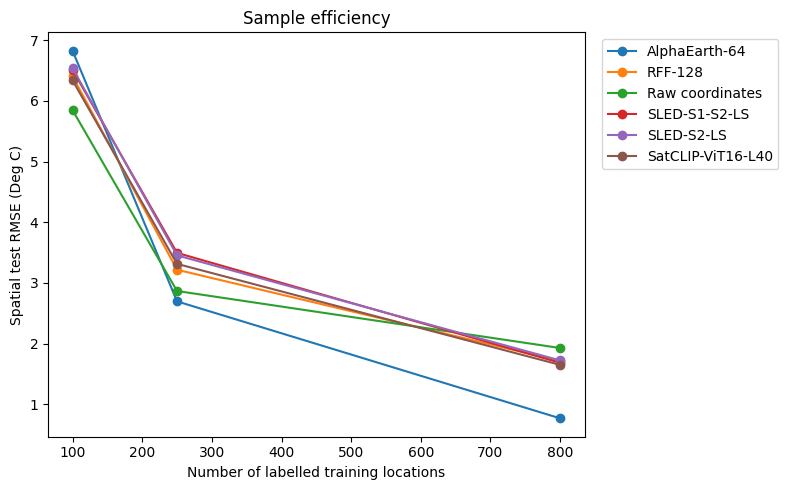

In [39]:
LABEL_COUNTS = [100, 250, 800]

SAMPLE_EFFICIENCY_REPS = [
    "Raw coordinates",
    "RFF-128",
    "SLED-S2-LS",
    "SLED-S1-S2-LS",
    "AlphaEarth-64",
]
SAMPLE_EFFICIENCY_REPS += [name for name in embedding_sets if name.startswith("SatCLIP")]
SAMPLE_EFFICIENCY_REPS = [name for name in SAMPLE_EFFICIENCY_REPS if name in embedding_sets]

# Keep validation completely separate from the label pool at every sample size.
label_pool = np.setdiff1d(train_idx, labeled_val_idx)

sample_efficiency_rows = []

for n_labels in LABEL_COUNTS:
    rng = np.random.default_rng(SEED + n_labels)
    sampled_train_idx = sample_across_blocks(label_pool, block_id, n_labels, rng)

    for rep_name in SAMPLE_EFFICIENCY_REPS:
        X = embedding_sets[rep_name]
        model, _ = fit_linear_probe(
            X[sampled_train_idx], y[sampled_train_idx],
            X[labeled_val_idx], y[labeled_val_idx]
        )
        pred = model.predict(X[test_idx], verbose=0).reshape(-1)
        metrics = regression_metrics(y[test_idx], pred)
        sample_efficiency_rows.append({
            "Labels": n_labels,
            "Representation": rep_name,
            **metrics,
        })

sample_efficiency_df = pd.DataFrame(sample_efficiency_rows)
display(sample_efficiency_df.sort_values(["Labels", "RMSE"]))

plt.figure(figsize=(8, 5))
for rep_name, group in sample_efficiency_df.groupby("Representation"):
    group = group.sort_values("Labels")
    plt.plot(group["Labels"], group["RMSE"], marker="o", label=rep_name)

plt.xlabel("Number of labelled training locations")
plt.ylabel(f"Spatial test RMSE ({TARGET_UNITS})" if TARGET_UNITS else "Spatial test RMSE")
plt.title("Sample efficiency")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### SLED and AlphaEarth deployment paths

This notebook intentionally uses the representations differently:

**SLED** runs directly from the released checkpoint. You provide `(lon, lat)` and obtain the embedding. The notebook caches the full NZ embedding matrix locally so repeated class runs are fast, but the cache is only a convenience — SLED can be queried at a completely new coordinate immediately.

That is the practical appeal of a coordinate network / INR-style representation: instead of distributing a giant table containing one vector for every possible location, much of the learned geographic representation is compressed into the model weights and evaluated continuously wherever we need it.

**AlphaEarth** is a class data product I provide. I sample the vectors once for the same climate-grid `row_id`s and share:

```text
nz_alphaearth_2024.npz
```

The file contains:

```text
row_id        shape (N,)
alphaearth    shape (N, 64)
elevation_m   shape (N,)
```

This difference is pedagogically useful: SLED is a continuous function of coordinates after pretraining, whereas AlphaEarth is an EO-derived embedding product that must be sampled for the prediction location/year.


## 15. OPTIONAL: a tiny nonlinear probe

A linear probe investigates how **linearly accessible** the target is in an embedding. A small MLP asks a different question: is the information present but arranged nonlinearly?

How do they compare in our case?

In [40]:
def fit_small_mlp(X_train, y_train, X_val, y_val):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    normalizer = layers.Normalization(axis=-1)
    normalizer.adapt(X_train)

    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        normalizer,
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.10),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse",
        metrics=[keras.metrics.RootMeanSquaredError(name="rmse")]
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=300,
        batch_size=64,
        callbacks=[early_stop],
        verbose=0
    )
    return model, history


NONLINEAR_REPS = ["SLED-S2-LS", "AlphaEarth-64"]
NONLINEAR_REPS += [name for name in embedding_sets if name.startswith("SatCLIP")]
NONLINEAR_REPS = [name for name in NONLINEAR_REPS if name in embedding_sets]

nonlinear_rows = []
nonlinear_models = {}

for rep_name in NONLINEAR_REPS:
    X = embedding_sets[rep_name]

    # Reuse the linear-probe prediction from the controlled comparison.
    linear_pred = test_predictions[rep_name]
    nonlinear_rows.append({
        "Representation": rep_name,
        "Probe": "Linear",
        **regression_metrics(y[test_idx], linear_pred),
    })

    mlp, history = fit_small_mlp(
        X[labeled_train_idx], y[labeled_train_idx],
        X[labeled_val_idx], y[labeled_val_idx]
    )
    mlp_pred = mlp.predict(X[test_idx], verbose=0).reshape(-1)
    nonlinear_models[rep_name] = mlp
    nonlinear_rows.append({
        "Representation": rep_name,
        "Probe": "Small MLP",
        **regression_metrics(y[test_idx], mlp_pred),
    })

nonlinear_df = pd.DataFrame(nonlinear_rows)[
    ["Representation", "Probe", "RMSE", "MAE", "R2"]
]
nonlinear_df.sort_values(["Representation", "Probe"]).reset_index(drop=True)


,Representation,Probe,RMSE,MAE,R2
0,AlphaEarth-64,Linear,0.754331,0.592919,0.925706
1,AlphaEarth-64,Small MLP,0.948404,0.744655,0.882560
2,SLED-S2-LS,Linear,1.626889,1.201133,0.654424
3,SLED-S2-LS,Small MLP,1.645479,1.247259,0.646481
4,SatCLIP-ViT16-L40,Linear,1.612063,1.237144,0.660694
5,SatCLIP-ViT16-L40,Small MLP,1.477821,1.115489,0.714851


## 16. Assignment: choose a different climate target

We will work through **mean annual temperature** together in class first. For your assignment, choose **one** alternative target from the same `nz_climate_targets_multivariable.npz` file.

You do **not** need a different file, Drive link, or coordinate conversion. Go back to Section 2 and change only:

```python
TARGET_KEY = "T_ANN_baseline_1995_2014"
```

to the key you want. For example:

```python
TARGET_KEY = "PR_ANN_baseline_1995_2014"         # annual rainfall
# TARGET_KEY = "TX25_ANN_baseline_1995_2014"     # hot days >25 C
# TARGET_KEY = "R99pVAL_ANN_baseline_1995_2014"  # heavy-rainfall intensity
```

Then run the notebook for yoru variable. You can make changes if need be, but conditions must be the same accross different models.

The complete target catalog is printed near the start of the notebook. Some especially useful choices are:

| Target key | What it represents |
|---|---|
| `PR_ANN_baseline_1995_2014` | total annual rainfall |
| `R99pVAL_ANN_baseline_1995_2014` | 99th-percentile heavy-rainfall value |
| `R99pVALWet_ANN_baseline_1995_2014` | 99th-percentile rainfall on wet days |
| `RR25mm_ANN_baseline_1995_2014` | number of very rainy days (>25 mm) |
| `DD1mm_ANN_baseline_1995_2014` | number of dry days (<1 mm) |
| `PEDsrad_ANN_baseline_1995_2014` | potential evapotranspiration deficit |
| `hurs_ANN_baseline_1995_2014` | average relative humidity |
| `rsds_ANN_baseline_1995_2014` | incoming solar radiation |
| `sfcWind_ANN_baseline_1995_2014` | average 10 m wind speed |
| `Wd99pVAL_ANN_baseline_1995_2014` | 99th-percentile strong wind |
| `TX25_ANN_baseline_1995_2014` | number of hot days (>25 C) |
| `FD_ANN_baseline_1995_2014` | number of frost days |

The file also contains several **late-century SSP3-7.0 change fields**. These can be interesting, but remember that predicting a climate-change signal is a different scientific question from reconstructing a historical baseline field.

For whichever target you choose:

- briefly justify why you chose it;
- revisit the train/test distributions and change the spatial split only if you can justify doing so;
- follow the same representation comparisons and answer the thought questions throughout for **your** variable;
- interpret elevation in the context of your target rather than assuming it must help;
- consider whether the target is smooth, threshold-based, or an extreme statistic when interpreting errors;
- you may add other ancillary variables, direct satellite observations, or field observations if they are scientifically appropriate.


## 17. Final discussion

Answer the following for the target you analysed.

1. Did SLED improve on raw coordinates and on the untrained RFF baseline?
2. How did **AlphaEarth** compare with SLED under the same TensorFlow linear probe?
3. Why is SLED versus AlphaEarth not a perfectly apples-to-apples comparison?
4. Were the two SLED pretraining-modality combinations meaningfully different?
5. Did pretrained embeddings help most when labels were sparse?
6. How strong was the **elevation-only** baseline?
7. What changed when elevation was added to SLED, SatCLIP, and AlphaEarth?
8. Where did the embedding-only and embedding+elevation residual maps differ spatially?
9. Why is a random train/test split likely to overestimate real mapping performance?
10. What does the SatCLIP comparison suggest about contrastive versus distillation-based location pretraining on this task?
11. Did the small nonlinear probe change your interpretation of what information was present in the embeddings?

Your conclusion should distinguish **predictive evidence** from claims about physical understanding. A low RMSE does not by itself prove that a model has learned climate physics.


---
## Sources and further reading

- New Zealand Ministry for the Environment, **Climate Projections Core Public Dataset**:  
  https://climatedata.environment.govt.nz/core-public-dataset.html
- **User guidance of CMIP6 downscaled data for Aotearoa New Zealand** (indicator definitions used for the assignment targets):  
  https://climatedata.environment.govt.nz/files/CMIP6_guidance_doc_June2024.pdf
- Lane, Wang, Rolf & Karimzadeh, **SLED: Scalable Location Encoding via Distillation**:  
  https://arxiv.org/abs/2608.06612
- SLED code / pip package:  
  https://github.com/geohai/sled
- Released SLED weights:  
  https://huggingface.co/geohai
- Google Earth Engine, **Satellite Embedding V1 / AlphaEarth Foundations**:  
  https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL
- SatCLIP implementation and pretrained checkpoints:  
  https://github.com/microsoft/satclip
- GeoTessera:  
  https://github.com/ucam-eo/geotessera
- OlmoEarth documentation:  
  https://docs.olmoearth.allenai.org/
